In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from model.kmeans import KMeans

bài 2: phân cụm iris bằng kmeans from scratch
(model xây dựng trong /model/kmeans.py)

In [3]:
data = load_iris(as_frame=True)
data = data.frame

data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
# plot the data to the from scratch algoritm
X = data[data.columns[:2]].to_numpy()
y = data["target"].to_numpy()

model = KMeans()
res_center, label, it = model.fit(X, 3, 100)
print(res_center, label, it)

[[5.77358491 2.69245283]
 [5.006      3.428     ]
 [6.81276596 3.07446809]] [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 2 0 2 0 2 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0
 2 2 2 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0] 12


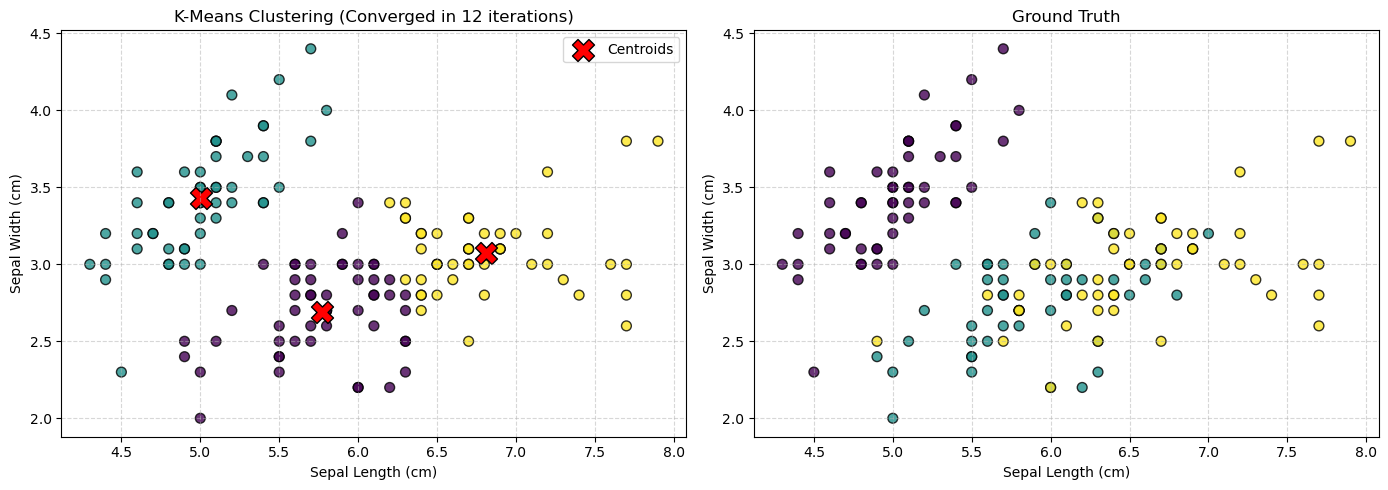

In [5]:
# visualization
X_np = np.asarray(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: K-Means Predicted Clusters & Centroids
scatter1 = axes[0].scatter(
    X_np[:, 0], X_np[:, 1], 
    c=label, cmap='viridis', s=50, alpha=0.8, edgecolors='k'
)
axes[0].scatter(
    res_center[:, 0], res_center[:, 1], 
    c='red', marker='X', s=250, edgecolors='black', label='Centroids'
)
axes[0].set_title(f'K-Means Clustering (Converged in {it} iterations)')
axes[0].set_xlabel('Sepal Length (cm)')
axes[0].set_ylabel('Sepal Width (cm)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Actual Ground Truth Labels
scatter2 = axes[1].scatter(
    X_np[:, 0], X_np[:, 1], 
    c=y, cmap='viridis', s=50, alpha=0.8, edgecolors='k'
)
axes[1].set_title('Ground Truth')
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

bài 3: Xác định k bằng elbow method

c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

1 30210.765042399427
2 14726.117037953445
3 3648.763582876105
4 3027.754035966964
5 923.9931490057969
6 843.7677420832543
7 769.5451688467292
8 714.6573133215312
9 673.0203258974311
10 640.3899290761109


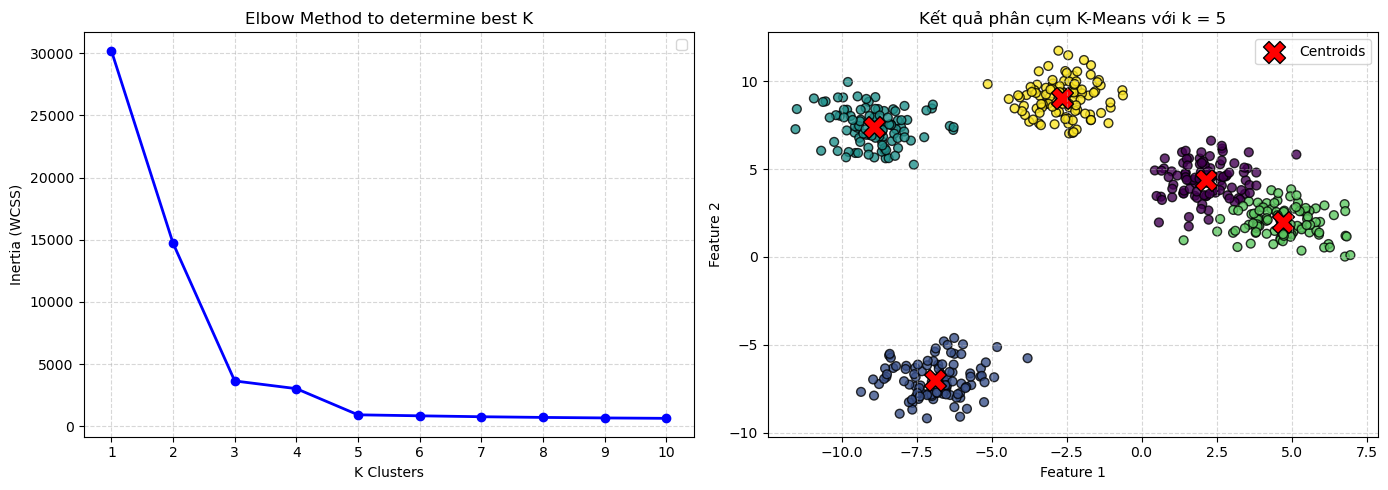

In [6]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, y_true = make_blobs(
    n_samples= 500,
    n_features= 2, # for visualization
    centers= 5,
    random_state= 42
)

inertias = []
for i in range(1, 11):
    model = KMeans(n_clusters= i, max_iter=100, random_state= 0, n_init="auto").fit(X)
    inertias.append(model.inertia_)
    print(i, model.inertia_)

# visualize the inertia changes to observe the elbow
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
k_values = range(1, 11)
axes[0].plot(k_values, inertias, marker='o', linestyle='-', color='b', linewidth=2)
axes[0].set_title('Elbow Method to determine best K')
axes[0].set_xlabel('K Clusters')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_xticks(k_values)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# ta có thể thấy trong biểu đồ, giá trị k=5 là số cụm tối ưu (inertia change from k=5 -> k=6 rất nhỏ)
# visualize dữ liệu với k=5
best_model = KMeans(n_clusters=5, max_iter=100, random_state=0, n_init="auto").fit(X)
axes[1].scatter(X[:, 0], X[:, 1], c=best_model.labels_, cmap='viridis', s=40, alpha=0.8, edgecolors='k')
axes[1].scatter(
    best_model.cluster_centers_[:, 0], best_model.cluster_centers_[:, 1], 
    c='red', marker='X', s=250, edgecolors='black', label='Centroids'
)
axes[1].set_title('Kết quả phân cụm K-Means với k = 5')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

bài 4: Nén ảnh bằng KMeans

Unique colors in original image : 37,205 colors
Actual Color Compression Ratio  : 2325.31 : 1 (Reduced by 99.96%)


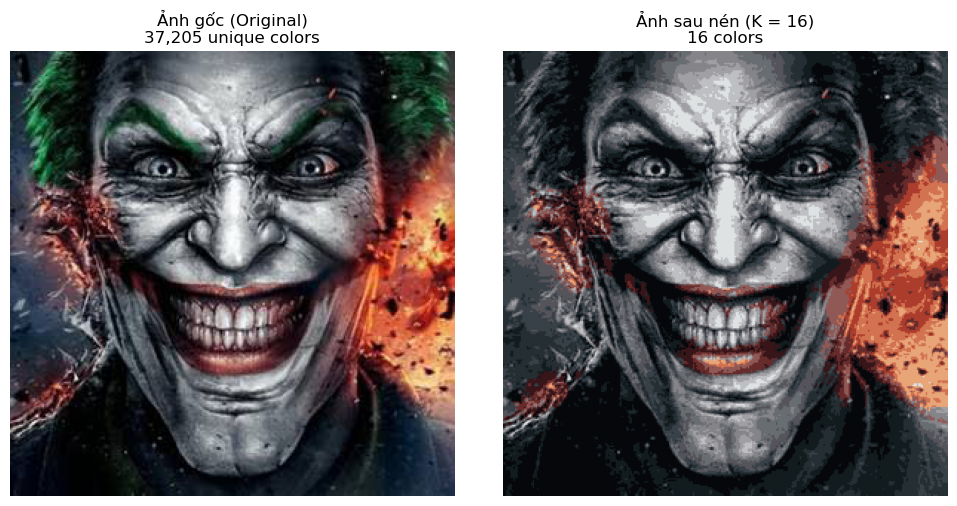

In [7]:
from PIL import Image

image_path = "data/jonkler.jpg"
img = Image.open(image_path).convert('RGB')
img_np = np.array(img) # this should return a 3D tensor of shape (300, 300, 3)
h, w, c = img_np.shape

# print(img_np.shape)
pixels = img_np.reshape(-1, 3) # compress this into a pixel array (90k per channel)
unique_original_colors = len(np.unique(pixels, axis=0))
# print(unique_original_colors)

# apply kmeans
kmeans = KMeans(n_clusters=16, random_state=42, n_init=10)
kmeans.fit(pixels)

centroids = np.round(kmeans.cluster_centers_).astype(np.uint8)
compressed_pixels = centroids[kmeans.labels_]

compressed_img_np = compressed_pixels.reshape(h, w, c)

# calculate compression ratio
actual_color_ratio = unique_original_colors / 16 # divides by amount of k
print(f"Unique colors in original image : {unique_original_colors:,} colors")
print(f"Actual Color Compression Ratio  : {actual_color_ratio:.2f} : 1 (Reduced by {(1 - 16/unique_original_colors)*100:.2f}%)")

# visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img_np)
axes[0].set_title(f"Ảnh gốc (Original)\n{unique_original_colors:,} unique colors")
axes[0].axis('off')

axes[1].imshow(compressed_img_np)
axes[1].set_title(f"Ảnh sau nén (K = {16})\n{16} colors")
axes[1].axis('off')

plt.tight_layout()
plt.show()

bài 5: So sánh kmeans với 2 cách khởi tạo: random và kmeans++

c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

Random Init    -> Min: 3648.76 | Max: 14656.14 | Mean: 4199.13 | Std: 2399.00
K-Means++ Init -> Min: 3648.76 | Max: 3648.76 | Mean: 3648.76 | Std: 0.00


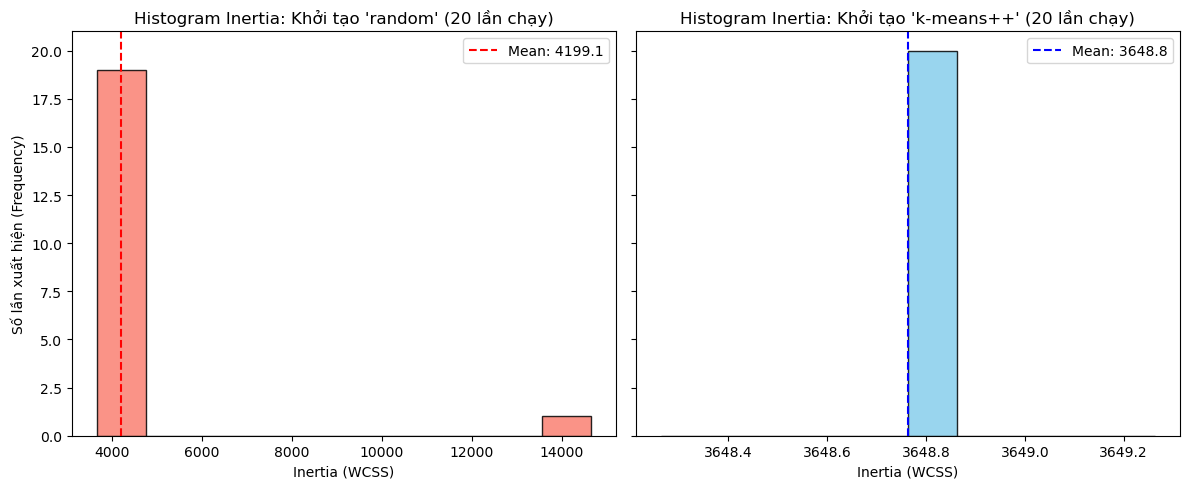

In [8]:
from sklearn.datasets import make_classification

# use make_classification to generate data
X_class, y_class = make_classification(
    n_samples=600,
    n_features=2,            # 2D dataset
    n_informative=2,         # Both features carry cluster info
    n_redundant=0,           # Must be 0 when n_features=2
    n_repeated=0,
    n_classes=3,             # 3 clusters
    n_clusters_per_class=1,  # CRITICAL: 3 * 1 <= 2^2 (4 corners)
    class_sep=2.5,           # Push the 3 clusters apart so they don't overlap too much
    flip_y=0.0,              # 0 noise so clusters stay clean
    random_state=42
)

# Apply a linear transformation matrix to guarantee they are extra long, narrow, and tilted
transformation = np.array([[0.6, -0.6], 
                           [-0.4, 0.8]])
X_class_stretched = np.dot(X_class, transformation)

max_iter = 20
K = 3
inertia_random = []
inertia_kmeans_pp = []

for seed in range(max_iter):
    km_rand = KMeans(n_clusters=K, init='random', n_init=1, random_state=seed)
    km_rand.fit(X)
    inertia_random.append(km_rand.inertia_)
    
    km_pp = KMeans(n_clusters=K, init='k-means++', n_init=1, random_state=seed)
    km_pp.fit(X)
    inertia_kmeans_pp.append(km_pp.inertia_)

print(f"Random Init    -> Min: {min(inertia_random):.2f} | Max: {max(inertia_random):.2f} | Mean: {np.mean(inertia_random):.2f} | Std: {np.std(inertia_random):.2f}")
print(f"K-Means++ Init -> Min: {min(inertia_kmeans_pp):.2f} | Max: {max(inertia_kmeans_pp):.2f} | Mean: {np.mean(inertia_kmeans_pp):.2f} | Std: {np.std(inertia_kmeans_pp):.2f}")

# 3. Plot the Histograms of Inertia for both methods
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].hist(inertia_random, bins=10, color='salmon', edgecolor='black', alpha=0.85)
axes[0].set_title("Histogram Inertia: Khởi tạo 'random' (20 lần chạy)")
axes[0].set_xlabel("Inertia (WCSS)")
axes[0].set_ylabel("Số lần xuất hiện (Frequency)")
axes[0].axvline(np.mean(inertia_random), color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {np.mean(inertia_random):.1f}')
axes[0].legend()

axes[1].hist(inertia_kmeans_pp, bins=10, color='skyblue', edgecolor='black', alpha=0.85)
axes[1].set_title("Histogram Inertia: Khởi tạo 'k-means++' (20 lần chạy)")
axes[1].set_xlabel("Inertia (WCSS)")
axes[1].axvline(np.mean(inertia_kmeans_pp), color='blue', linestyle='dashed', linewidth=1.5, label=f'Mean: {np.mean(inertia_kmeans_pp):.1f}')
axes[1].legend()

plt.tight_layout()
plt.show()

bài 6: "Tính tay" DBSCAN 1 chiều

In [11]:
from model.dbscan import DBSCANScratch
X_1d = np.array([1, 2, 3, 10, 11, 12, 50])
eps = 2
min_pts = 2

model = DBSCANScratch(epsilon=eps, min_samples=min_pts)
labels = model.fit_predict(X_1d)
summary = model.get_summary(X_1d)

print("=== KẾT QUẢ DBSCAN ===")
print(f"Tập điểm ban đầu : {X_1d.tolist()}")
print(f"Nhãn phân cụm    : {labels.tolist()}")
print("-" * 48)
print(f"Core Points (Điểm lõi)   : {summary['core_points']}")
print(f"Border Points (Điểm biên): {summary['border_points']}")
print(f"Noise Points (Điểm nhiễu): {summary['noise_points']}")
print("-" * 48)
for cluster_name, points in summary["clusters"].items():
    print(f"{cluster_name}: {points}")

=== KẾT QUẢ DBSCAN ===
Tập điểm ban đầu : [1, 2, 3, 10, 11, 12, 50]
Nhãn phân cụm    : [0, 0, 0, 1, 1, 1, -1]
------------------------------------------------
Core Points (Điểm lõi)   : [1, 2, 3, 10, 11, 12]
Border Points (Điểm biên): []
Noise Points (Điểm nhiễu): [50]
------------------------------------------------
Cluster 1: [1, 2, 3]
Cluster 2: [10, 11, 12]


bài 7: So sánh DBSCANScratch và sklearn DBSCAN

Nhãn khớp nhau 100%: True
Số điểm Core (MyDBSCAN): 300
Số điểm Core (Sklearn) : 300
Số điểm Noise (MyDBSCAN): 27
Số điểm Noise (Sklearn) : 27


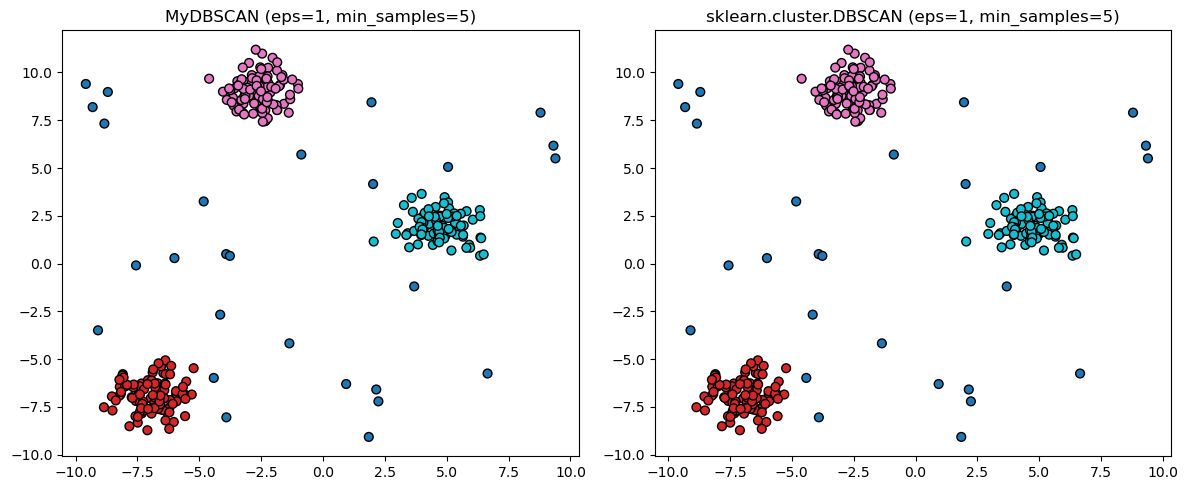

In [ ]:
from sklearn.cluster import DBSCAN

# generate random dataset
np.random.seed(42)
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)
X_noise = np.random.uniform(low=-10, high=10, size=(30, 2))
X_data = np.vstack([X_blobs, X_noise])

# DBSCAN from scratch
eps = 1
min_samples = 5
my_model = DBSCANScratch(epsilon=eps, min_samples=min_samples)
my_labels = my_model.fit_predict(X_data)

# sklearn DBSCAN
sk_model = DBSCAN(eps=eps, min_samples=min_samples)
sk_labels = sk_model.fit_predict(X_data)

print("Nhãn khớp nhau 100%:", np.array_equal(my_labels, sk_labels))
print("Số điểm Core (MyDBSCAN):", np.sum(my_model.is_core_))
print("Số điểm Core (Sklearn) :", len(sk_model.core_sample_indices_))
print("Số điểm Noise (MyDBSCAN):", np.sum(my_model.is_noise_))
print("Số điểm Noise (Sklearn) :", np.sum(sk_labels == -1))

# visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_data[:, 0], X_data[:, 1], c=my_labels, cmap='tab10', s=40, edgecolor='k')
axes[0].set_title(f"DBSCANScratch (eps={eps}, min_samples={min_samples})")

axes[1].scatter(X_data[:, 0], X_data[:, 1], c=sk_labels, cmap='tab10', s=40, edgecolor='k')
axes[1].set_title(f"sklearn.cluster.DBSCAN (eps={eps}, min_samples={min_samples})")

plt.tight_layout()
plt.show()